# DHVC restart slice viewer

Reads a restart folder (`U/V/W/T/P.bin` = raw float64, C-order, no header; `meta.txt` gives dims) and shows a **slice in a chosen direction for all 5 variables**.

- Field layout `F[i,j,k]`: `i=x` (vertical/streamwise), `j=y` (span), `k=z` (wall-normal). Domain `Lx×Ly×Lz = 8×4×1`.
- `axis` = slice-normal (`'x'`,`'y'`,`'z'`); `pos` = `0..1` fraction of the domain (0.5 = middle) or `>1` = explicit cell index.

Edit `RESTART_DIR` then run the call cell with whatever `axis`/`pos` you want.

In [1]:
import numpy as np, os
import matplotlib.pyplot as plt
%matplotlib inline

# restart 폴더를 실행 CWD에 무관하게 해석 (노트북 위치 = apps/dhvc 기준)
APP_DIR = "/shared/home/wel1come1234/workspace/MPM-STD_C/apps/dhvc"
if not os.path.isdir(APP_DIR):
    APP_DIR = os.getcwd()

def resolve_restart(name):
    """절대경로면 그대로, 아니면 APP_DIR 기준 또는 basename 으로 탐색."""
    for cand in (name, os.path.join(APP_DIR, name),
                 os.path.join(APP_DIR, os.path.basename(name))):
        if os.path.isdir(cand):
            return cand
    return os.path.join(APP_DIR, os.path.basename(name))

RESTART_DIR = resolve_restart("restart_1e8")   # ← restart folder 이름만
L = {"x": 8.0, "y": 4.0, "z": 1.0}            # DHVC domain Lx,Ly,Lz

def _dims(d):
    n = {"n1m": 384, "n2m": 96, "n3m": 192}
    mp = os.path.join(d, "meta.txt")
    if os.path.exists(mp):
        for line in open(mp):
            t = line.split()
            if len(t) == 2 and t[0] in n:
                n[t[0]] = int(float(t[1]))
    return n["n1m"], n["n2m"], n["n3m"]

def load(d, name, n1, n2, n3):
    a = np.fromfile(os.path.join(d, f"{name}.bin"), dtype=np.float64)
    assert a.size == n1 * n2 * n3, f"{name}.bin size {a.size} != {n1*n2*n3} (check meta dims)"
    return a.reshape(n1, n2, n3)                # [x, y, z]

def plot_slice(axis="z", pos=0.5, d=None, vars=("U", "V", "W", "T", "P")):
    d = resolve_restart(d) if d else RESTART_DIR
    axis = axis.lower(); assert axis in ("x", "y", "z")
    n1, n2, n3 = _dims(d)
    na = {"x": n1, "y": n2, "z": n3}[axis]
    idx = int(round(pos * (na - 1))) if 0.0 <= pos <= 1.0 else int(pos)
    idx = max(0, min(na - 1, idx))
    phys = idx / (na - 1) * L[axis]
    coord = {"x": np.linspace(0, L["x"], n1),
             "y": np.linspace(0, L["y"], n2),
             "z": np.linspace(0, L["z"], n3)}
    def take(F):                                    # -> (slice[vert,horiz], vert, horiz)
        if axis == "x": return F[idx, :, :], "y", "z"
        if axis == "y": return F[:, idx, :], "x", "z"
        return F[:, :, idx], "x", "y"
    vert, horiz = {"x": ("y", "z"), "y": ("x", "z"), "z": ("x", "y")}[axis]
    sub_w = 4.6                                       # 서브플롯 가로(inch)
    sub_h = max(1.3, min(4.6, sub_w * L[vert] / L[horiz]))  # 실제 도메인 종횡비
    fig, axes = plt.subplots(2, 3, figsize=(3 * sub_w + 1.5, 2 * sub_h + 1.6))
    fig.suptitle(f"{d}   slice {axis}={idx} (phys {axis}={phys:.3g})   grid {n1}x{n2}x{n3}")
    for ax, name in zip(axes.flat, vars):
        F = load(d, name, n1, n2, n3)
        sl, vert, horiz = take(F)
        cmap = "coolwarm" if name == "T" else "RdBu_r"
        im = ax.pcolormesh(coord[horiz], coord[vert], sl, shading="auto", cmap=cmap)
        ax.set(title=f"{name}  [{sl.min():.3g}, {sl.max():.3g}]", xlabel=horiz, ylabel=vert)
        ax.set_aspect("equal")                       # 실제 도메인 종횡비(1:1) 반영
        fig.colorbar(im, ax=ax, fraction=0.046)
    for ax in axes.flat[len(vars):]:
        ax.axis("off")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

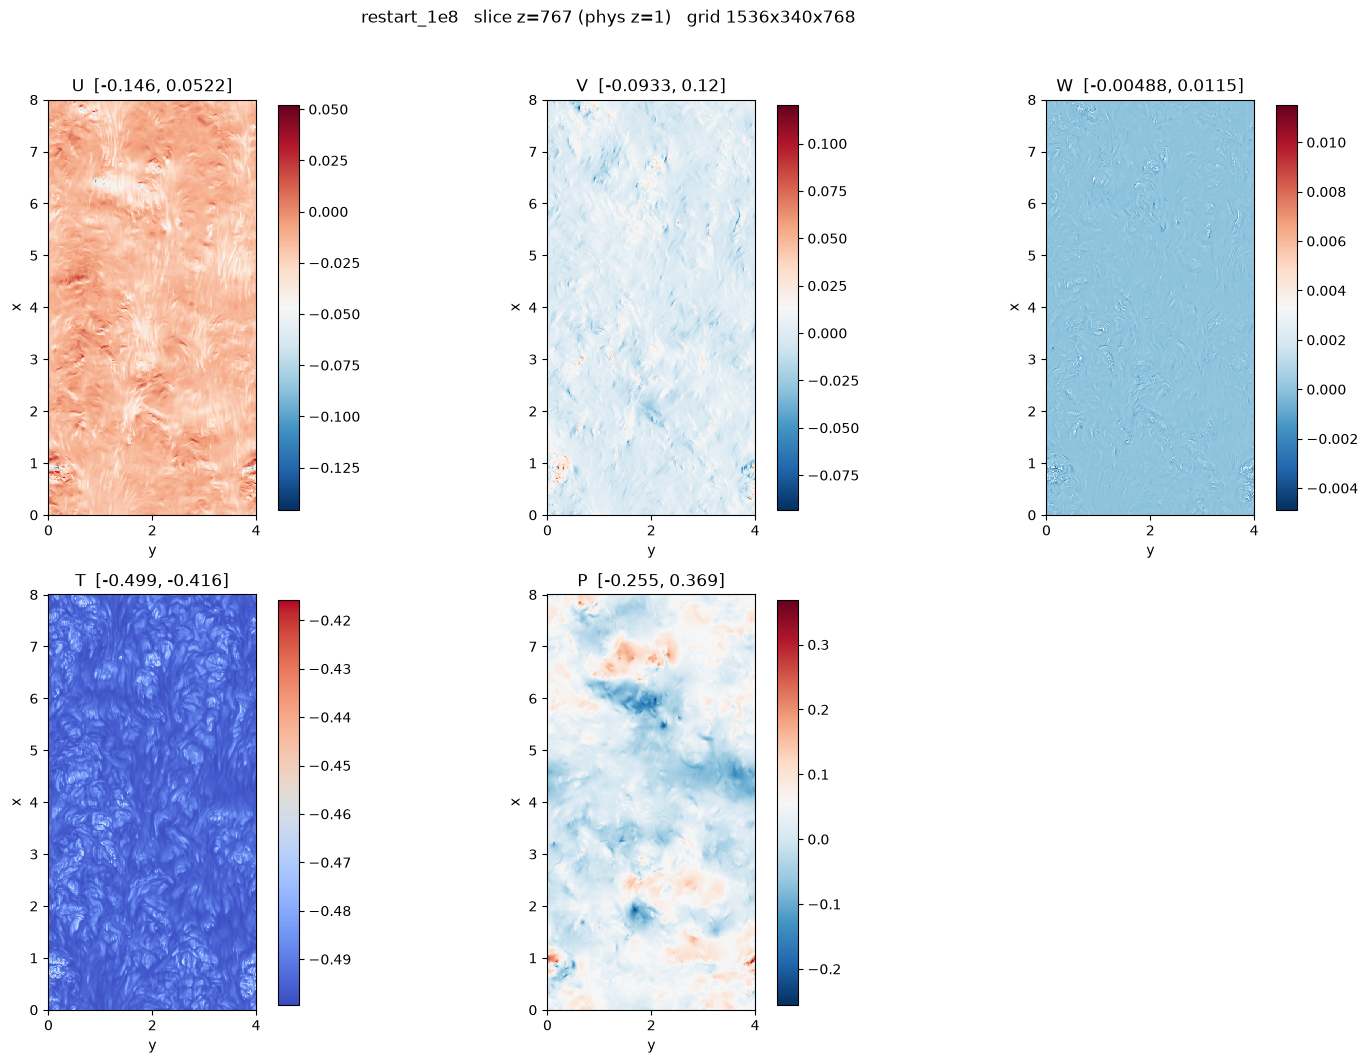

In [5]:
# axis = 'x'|'y'|'z' (slice-normal),  pos = 0..1 fraction (0.5=middle) or >1 = cell index
plot_slice("z", 1 - 0.0001)    # mid-gap x-y plane

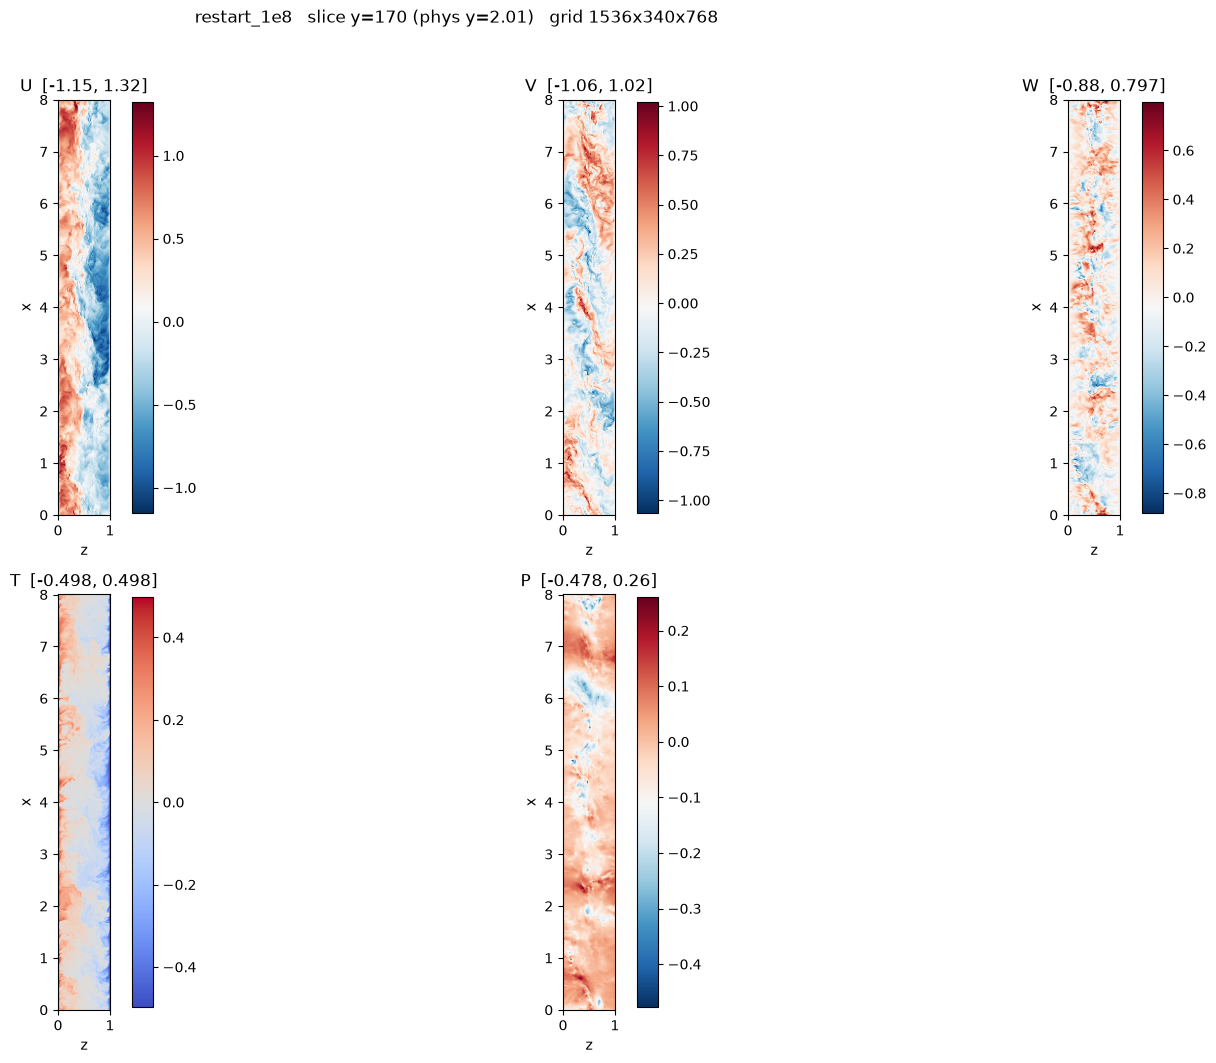

In [3]:
plot_slice("y", 0.5)    # mid-span x-z plane (vertical x vs wall-normal z)